# KEA3 tomato drought trial: ECS re-fit from the openJII raw traces

Reproduces the ECSt and gH+ values used in **Figure 4** of von Bismarck et al.,
*Experimental and computational analysis of KEA3 function in the vegetable crop tomato compared with Arabidopsis*,
directly from the MultispeQ data hosted on openJII.

For this dataset the PhotosynQ macro's exponential fit of the 520 nm electrochromic shift (ECS) decay does not hold up
on every trace, so every trace is re-fitted the same way: linear baseline from the first 18 points, offset to point 19, single exponential `a * exp(-t / tau) + c`
on points 19 to 40 with 1.5 time units per point. `ECSt_calc = a`, `gH+_refit = 1000 / tau`.
The fitting code is Thekla von Bismarck's (see `notebooks/original/`), unchanged except for reading the traces from the
openJII API instead of a CSV export.

**Data**: openJII experiment [KEA3 tomato drought trial (MultispeQ, RL3)](https://openjii.org/en-US/platform/experiments/e0acb807-5a1a-4f35-8902-a1d8629d4cc9),
1,380 Photosynthesis RIDES 2.0 measurements, Potsdam, 21, 22 and 28 July 2022.

**Setup**: copy `.env.example` to `.env` and put your personal openJII API key in it
(openjii.org → Profile menu → Account → API keys). Then `uv sync` and run this notebook. The first run downloads the data
into `data/raw/` (git-ignored); later runs read the local copy.

## 0. Configuration

In [1]:
import json, os, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import requests
from dotenv import load_dotenv
from scipy.optimize import curve_fit
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_RAW = ROOT / "data" / "raw"
DATA_PROCESSED = ROOT / "data" / "processed"
OUTPUTS = ROOT / "outputs"
for p in (DATA_RAW, DATA_PROCESSED, OUTPUTS):
    p.mkdir(parents=True, exist_ok=True)

load_dotenv(ROOT / ".env")
API_KEY = os.environ.get("OPENJII_API_KEY")
if not API_KEY:
    raise SystemExit(
        "OPENJII_API_KEY is not set. Copy .env.example to .env and paste your personal API key "
        "(openjii.org -> Profile menu -> Account -> API keys)."
    )

API = "https://api.openjii.org/api/v1"
EXPERIMENT_ID = "e0acb807-5a1a-4f35-8902-a1d8629d4cc9"
HEADERS = {"x-api-key": API_KEY}
print("data dir:", DATA_RAW)

data dir: /home/dv/code/work/kea3-tomato-ecs-refit/data/raw


## 1. Fetch the processed RIDES table from openJII

Cached as parquet in `data/raw/` after the first download. Delete the file to refresh.

In [2]:
RAW_PARQUET = DATA_RAW / "rides_processed.parquet"
TABLES_JSON = DATA_RAW / "tables.json"


def api_get(path, **params):
    # The API rate-limits per key (HTTP 429); back off and retry instead of failing the run.
    for attempt in range(8):
        r = requests.get(f"{API}/experiments/{EXPERIMENT_ID}/{path}", headers=HEADERS, params=params, timeout=120)
        if r.status_code == 429:
            wait = int(r.headers.get("Retry-After", 0)) or 2 ** attempt
            print(f"rate limited on {path}, retrying in {wait}s")
            time.sleep(wait)
            continue
        r.raise_for_status()
        return r.json()
    r.raise_for_status()


def fetch_table(table_id, page_size=100):
    # /data pages at most 100 rows. The response envelope carries the table total in
    # payload[0]["totalRows"]; payload[0]["data"]["totalRows"] is the rows on this page.
    rows, page, total = [], 1, None
    while total is None or len(rows) < total:
        payload = api_get("data", tableName=table_id, page=page, pageSize=page_size)
        envelope = payload[0] if isinstance(payload, list) else payload
        data = envelope.get("data", envelope)
        total = envelope.get("totalRows", total)
        if not data["rows"]:
            break
        rows += data["rows"]
        page += 1
    return pd.DataFrame(rows)


if RAW_PARQUET.exists():
    raw = pd.read_parquet(RAW_PARQUET)
    print("loaded cached", RAW_PARQUET.name, raw.shape)
else:
    tables = api_get("tables")
    TABLES_JSON.write_text(json.dumps(tables, indent=1))
    macro_table = next(t for t in tables if t["tableType"] == "macro")
    print("downloading", macro_table["displayName"], "from openJII ...")
    raw = fetch_table(macro_table["identifier"])
    assert len(raw) == macro_table["totalRows"], (len(raw), macro_table["totalRows"])
    raw.to_parquet(RAW_PARQUET, index=False)
    print("saved", RAW_PARQUET.name, raw.shape)

raw["timestamp"] = pd.to_datetime(raw["timestamp"])
for c in ["NPQt", "ECSt mAU", "gH+", "ECS_tau", "Light Intensity (PAR)", "Phi2", "rep"]:
    raw[c] = pd.to_numeric(raw[c], errors="coerce")
print(len(raw), "measurements;", raw["timestamp"].dt.date.nunique(), "days;",
      raw["which_plant"].nunique(), "lines;", sorted(raw["condition"].unique()))

rate limited on tables, retrying in 1s


rate limited on tables, retrying in 2s


rate limited on tables, retrying in 4s


rate limited on tables, retrying in 8s


downloading Processed Data (Photosynthesis RIDES 2.0 (PhotosynQ)) from openJII ...


saved rides_processed.parquet (1380, 68)
1380 measurements; 3 days; 5 lines; ['Con', 'Dr', 'Rec']


## 2. Line codes and conditions

Confirmed by the authors (September 2026).

| `which_plant` | line |
|---|---|
| W | Moneymaker wild type |
| p1 | *slkea3-1* |
| p2 | *slkea3-2* |
| L7, L12 | the two *SlKEA3* overexpression lines (measured, not shown in Fig. 4) |

`condition`: **Con** = well watered, **Dr** = drought (watered once a week from week 4), **Rec** = re-watered recovery
(22 July only, not in the paper). 21 July = week 5, 28 July = week 6; Fig. 4 pools both weeks.

In [3]:
LINES = {"W": "M.M. (WT)", "p1": "slkea3-1", "p2": "slkea3-2", "L7": "oeSlKEA3 (L7)", "L12": "oeSlKEA3 (L12)"}
raw["line"] = raw["which_plant"].map(LINES)
pd.crosstab([raw["timestamp"].dt.date, raw["condition"]], raw["which_plant"])

which_plant           L12  L7   W  p1  p2
timestamp  condition                     
2022-07-21 Con         31  37  37  35  34
           Dr          41  43  44  44  43
2022-07-22 Con         42  44  44  43  41
           Rec         44  44  44  44  43
2022-07-28 Con         47  48  50  50  45
           Dr          62  64  63  64  65

## 3. Re-fit the ECS decay

`ECS_averaged_trace` holds 70 points per measurement. Steps, exactly as in the original notebook:

1. Linear regression on points 0 to 17 gives the baseline; subtract it from the whole trace.
2. Offset so that point 19 is zero.
3. Fit `a * exp(-t / tau) + c` to points 19 to 40, with `t = 0, 1.5, 3.0, ...`.
4. `ECSt_calc = a`, `tau_refit = tau`, `gH+_refit = 1000 / tau`.

In [4]:
def func4(t, a, tau, c):
    return a * np.exp(-t / tau) + c


def parse_trace(value):
    if value is None:
        return None
    seq = json.loads(value) if isinstance(value, str) else value
    return np.array([float(x) for x in seq], dtype=np.float32)


def refit_trace(trace):
    tdata = np.arange(0, 105, 1.5)[: len(trace)]
    ytime = trace[0:18].reshape(-1, 1)
    xtime = np.arange(len(ytime)).reshape(-1, 1)
    lr = LinearRegression().fit(xtime, ytime)
    baseline = tdata * lr.coef_[0][0] + lr.intercept_[0]
    ecs = trace - baseline
    ecs = ecs - ecs[19]
    fitdata = ecs[19:41]
    tfit = np.arange(0, 105, 1.5)[: len(fitdata)]
    (a, tau, c), _ = curve_fit(func4, tfit, fitdata)
    return a, tau, 1000.0 / tau, fitdata, tfit, func4(tfit, a, tau, c)


def refit_row(value):
    # Any failure (missing or malformed trace, fit not converging) yields NaN for that row only,
    # matching the original notebook's per-row error handling.
    try:
        trace = parse_trace(value)
        if trace is None:
            raise ValueError("no trace")
        a, tau, g, *_ = refit_trace(trace)
        return pd.Series({"ECSt_calc": a, "tau_refit": tau, "gH+_refit": g})
    except Exception:
        return pd.Series({"ECSt_calc": np.nan, "tau_refit": np.nan, "gH+_refit": np.nan})


refit = raw["ECS_averaged_trace"].apply(refit_row)
df = pd.concat([raw, refit], axis=1)
print("fits failed:", int(df["ECSt_calc"].isna().sum()), "of", len(df))
df[["ECSt mAU", "ECSt_calc", "gH+", "gH+_refit"]].describe().loc[["50%", "min", "max"]]

fits failed: 0 of 1380


,ECSt mAU,ECSt_calc,gH+,gH+_refit
50%,0.00099,0.001479,88.447,96.581545
min,-11.54616,-3.167618,-312630.063,-645.350219
max,0.07243,550.347122,3553.057,417629.229367


### Example fits

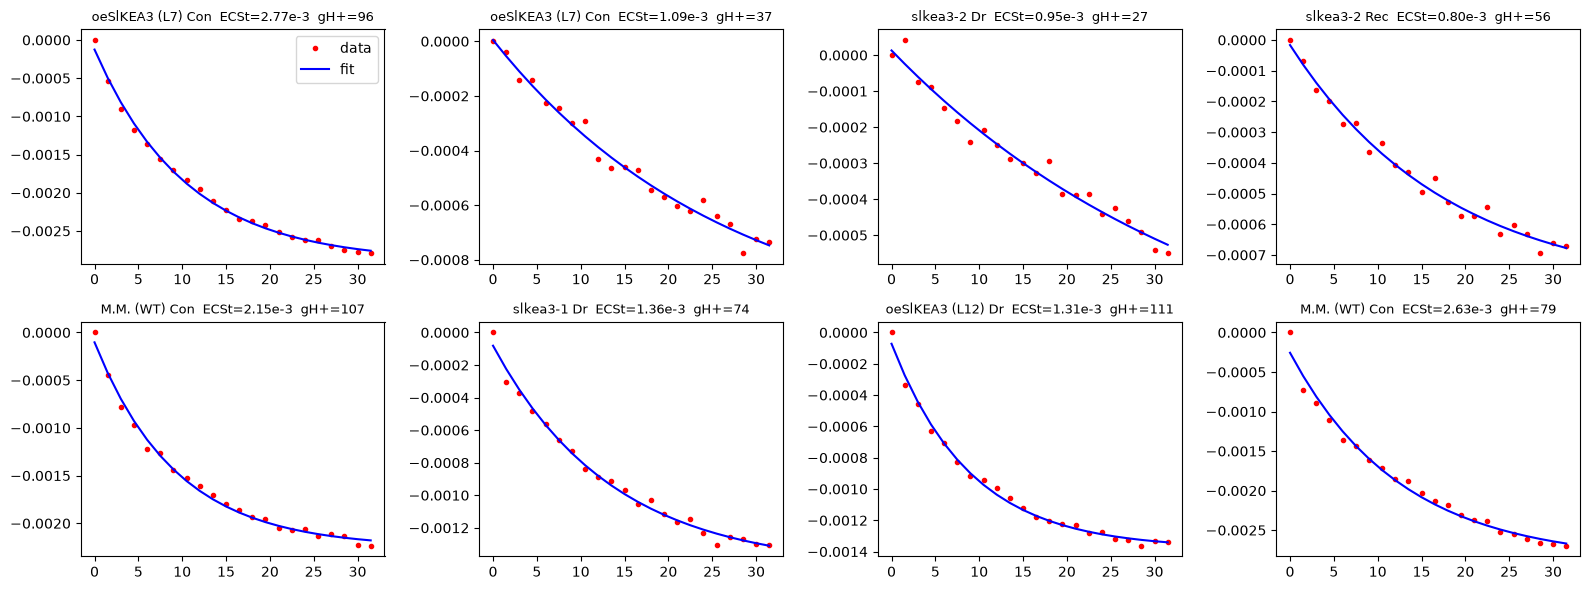

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
examples = df[df["Light Intensity (PAR)"] > 0].sample(8, random_state=1)
for ax, (_, row) in zip(axes.ravel(), examples.iterrows()):
    a, tau, g, fitdata, tfit, yfit = refit_trace(parse_trace(row["ECS_averaged_trace"]))
    ax.plot(tfit, fitdata, "r.", label="data")
    ax.plot(tfit, yfit, "b-", label="fit")
    ax.set_title(f"{row['line']} {row['condition']}  ECSt={a*1e3:.2f}e-3  gH+={g:.0f}", fontsize=9)
axes[0, 0].legend()
plt.tight_layout()
fig.savefig(OUTPUTS / "example_fits.png", dpi=150)

### Device macro values versus the re-fit

Within the plotted ranges the device macro's `ECSt mAU` and `gH+` track the re-fit closely (Pearson r about 0.96 and
0.94). The macro's weakness is the tail: on rows where its fit failed it returns extreme or negative values (ECSt down to
−11.5, gH+ to −3×10⁵), which the re-fit turns into well-behaved numbers. The paper therefore uses the re-fitted values.

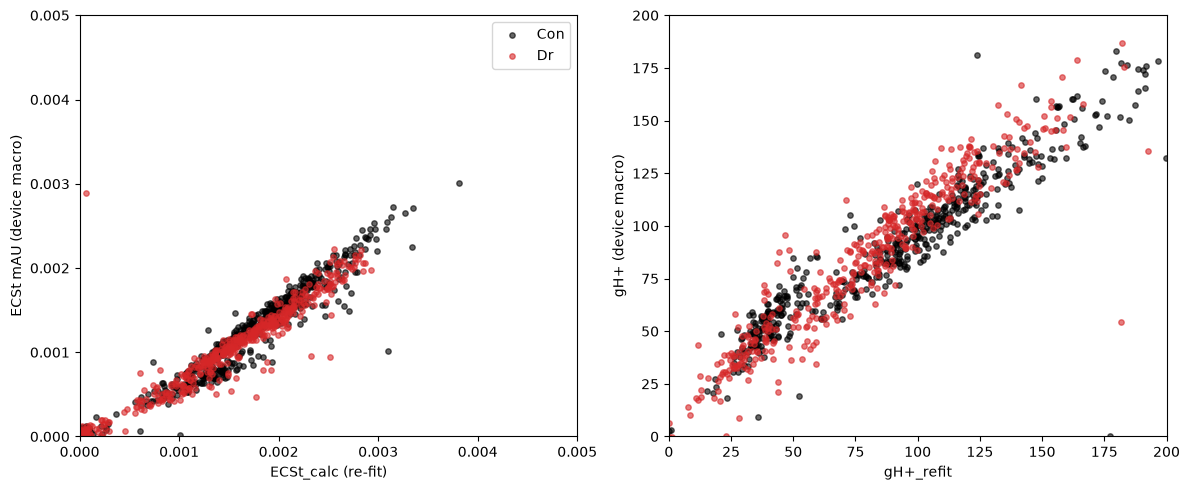

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for cond, col in [("Con", "black"), ("Dr", "tab:red")]:
    d = df[df["condition"] == cond]
    axes[0].scatter(d["ECSt_calc"], d["ECSt mAU"], s=15, color=col, label=cond, alpha=0.6)
    axes[1].scatter(d["gH+_refit"], d["gH+"], s=15, color=col, label=cond, alpha=0.6)
axes[0].set(xlim=(0, 0.005), ylim=(0, 0.005), xlabel="ECSt_calc (re-fit)", ylabel="ECSt mAU (device macro)")
axes[1].set(xlim=(0, 200), ylim=(0, 200), xlabel="gH+_refit", ylabel="gH+ (device macro)")
axes[0].legend()
plt.tight_layout()
fig.savefig(OUTPUTS / "refit_vs_macro.png", dpi=150)

## 4. Reproduce the Fig. 4 replicate counts

The manuscript legend gives N = 97 to 106 (Control) and N = 86 to 87 (Drought) per line. Filters as in the original
notebook: rows with `Light Intensity (PAR)` = 0 excluded (PAR ≠ 0; those rows were measured on a different day / sensor covered),
`0 <= ECSt_calc <= 0.004`, `0 <= NPQt <= 5`, lines W, p1, p2.

In [7]:
def fig4_subset(cond):
    d = df[(df["condition"] == cond) & (df["Light Intensity (PAR)"] != 0)]
    return d[d["ECSt_calc"].between(0, 0.004) & d["NPQt"].between(0, 5) & d["which_plant"].isin(["W", "p1", "p2"])]


counts = pd.DataFrame({cond: fig4_subset(cond)["line"].value_counts() for cond in ["Con", "Dr"]})
expected = {"Con": {"M.M. (WT)": 106, "slkea3-1": 103, "slkea3-2": 97},
            "Dr": {"M.M. (WT)": 86, "slkea3-1": 87, "slkea3-2": 86}}
lines_md = ["| line | Control | Drought | matches legend |", "|---|---|---|---|"]
all_ok = True
for line in ["M.M. (WT)", "slkea3-1", "slkea3-2"]:
    ok = all(int(counts.loc[line, c]) == expected[c][line] for c in ["Con", "Dr"])
    all_ok &= ok
    lines_md.append(f"| {line} | {int(counts.loc[line, 'Con'])} | {int(counts.loc[line, 'Dr'])} | {'yes' if ok else 'NO'} |")
(OUTPUTS / "legend_counts.md").write_text(
    "# Fig. 4 replicate counts reproduced from openJII\n\n" + "\n".join(lines_md) + "\n")
print("\n".join(lines_md))
assert all_ok, "replicate counts do not match the manuscript legend"

| line | Control | Drought | matches legend |
|---|---|---|---|
| M.M. (WT) | 106 | 86 | yes |
| slkea3-1 | 103 | 87 | yes |
| slkea3-2 | 97 | 86 | yes |


## 5. Fig. 4 C and D: NPQt versus ECSt with kernel density shading

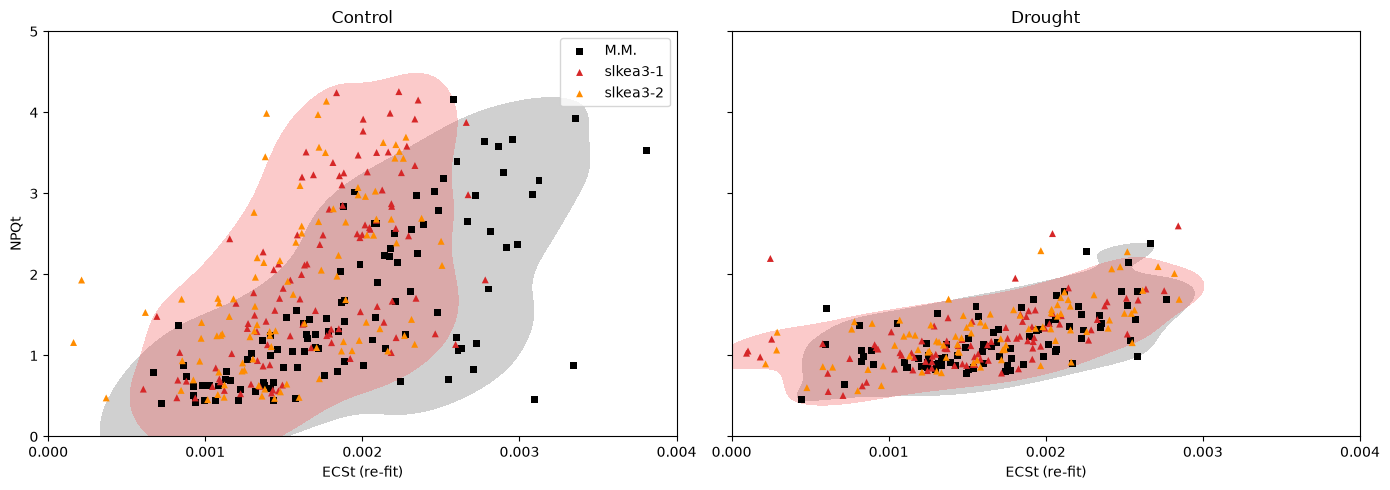

In [8]:
def plot_fig4(cond, title, ax):
    d = fig4_subset(cond)
    w = d[d["which_plant"] == "W"]
    p = d[d["which_plant"].isin(["p1", "p2"])]
    sns.kdeplot(x=w["ECSt_calc"], y=w["NPQt"], levels=[0.1, 1], color="grey", alpha=0.4, fill=True, ax=ax)
    sns.kdeplot(x=p["ECSt_calc"], y=p["NPQt"], levels=[0.1, 1], color="tab:red", alpha=0.3, fill=True, ax=ax)
    ax.scatter(w["ECSt_calc"], w["NPQt"], color="black", marker="s", s=25, label="M.M.", edgecolors="none")
    p1, p2 = d[d["which_plant"] == "p1"], d[d["which_plant"] == "p2"]
    ax.scatter(p1["ECSt_calc"], p1["NPQt"], color="tab:red", marker="^", s=25, label="slkea3-1", edgecolors="none")
    ax.scatter(p2["ECSt_calc"], p2["NPQt"], color="darkorange", marker="^", s=25, label="slkea3-2", edgecolors="none")
    ax.set(xlim=(0, 0.004), ylim=(0, 5), xlabel="ECSt (re-fit)", ylabel="NPQt", title=title)
    ax.set_xticks(np.arange(0, 0.0041, 0.001))


fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
plot_fig4("Con", "Control", axes[0])
plot_fig4("Dr", "Drought", axes[1])
axes[0].legend()
plt.tight_layout()
fig.savefig(OUTPUTS / "fig4_control_drought.png", dpi=150)

### The recovery day

Drought plants were re-watered and measured again on 22 July (`Rec`). Not part of the paper; shown because the data is there.

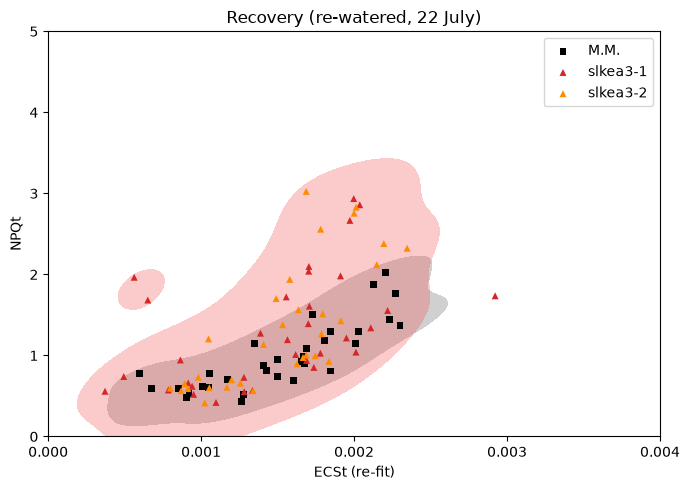

In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
plot_fig4("Rec", "Recovery (re-watered, 22 July)", ax)
ax.legend()
plt.tight_layout()
fig.savefig(OUTPUTS / "fig4_recovery.png", dpi=150)

## 6. Save the re-fitted values

One row per measurement, keyed on the openJII row `id`, written as parquet to `data/processed/` (git-ignored).
The same table is uploaded to the openJII experiment under the name `ecs_refit` (see the experiment's data tables).

In [10]:
export_cols = ["id", "device_id", "timestamp", "condition", "which_plant", "line", "rep",
               "Light Intensity (PAR)", "NPQt", "Phi2", "ECSt mAU", "gH+", "ECSt_calc", "tau_refit", "gH+_refit"]
export = df[export_cols].rename(columns={"Light Intensity (PAR)": "PAR", "ECSt mAU": "ECSt_macro",
                                         "gH+": "gH_macro", "gH+_refit": "gH_refit"})
export["id"] = export["id"].astype(str)
export["rep"] = export["rep"].astype("Int64")
out = DATA_PROCESSED / "ecs_refit.parquet"
export.to_parquet(out, index=False)
print(export.shape, "->", out)
export.head()

(1380, 15) -> /home/dv/code/work/kea3-tomato-ecs-refit/data/processed/ecs_refit.parquet


,id,device_id,timestamp,condition,which_plant,line,rep,PAR,NPQt,Phi2,ECSt_macro,gH_macro,ECSt_calc,tau_refit,gH_refit
0,453678268,01:12:37:34,2022-07-28 12:17:31.241000+00:00,Con,W,M.M. (WT),10,43.469,0.699,0.661,0.00064,84.620,0.001129,17.568087,56.921394
1,1637304852,01:12:37:34,2022-07-28 12:20:18.230000+00:00,Con,p1,slkea3-1,3,39.140,1.264,0.461,0.00096,23.459,0.001791,52.666318,18.987468
2,275775252,01:12:37:34,2022-07-28 12:27:24.600000+00:00,Con,L12,oeSlKEA3 (L12),8,37.000,1.099,0.598,0.00073,37.631,0.001117,26.198997,38.169400
3,629746920,01:12:37:34,2022-07-28 12:28:21.835000+00:00,Con,L12,oeSlKEA3 (L12),10,44.467,0.886,0.370,0.00115,20.790,0.001912,56.152452,17.808661
4,1122221291,01:12:37:34,2022-07-28 12:31:59.340000+00:00,Dr,p1,slkea3-1,11,36.561,0.976,0.599,0.00058,38.756,0.001164,38.971536,25.659754
